# Credit Card Customer Churn & Retention Analytics
## Exploratory Data Analysis (EDA)

### Business Context
Customer churn is an important challenge in the credit card industry, as losing existing customers can affect revenue, customer lifetime value, and long-term profitability.

This project analyzes customer demographic characteristics, financial behavior, transaction activity, and engagement patterns to better understand customer churn and identify potential retention opportunities.

### Business Objectives

## 1. Environment Setup

In [5]:
%pip install matplotlib seaborn

  Using cached matplotlib-3.11.2-cp313-cp313-win_amd64.whl.metadata (80 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached contourpy-1.4.0-cp313-cp313-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp313-cp313-win_amd64.whl.metadata (5.2 kB)
  Using cached pillow-12.3.0-cp313-cp313-win_amd64.whl.metadata (9.3 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp313-cp313-win_amd64.whl (9.3 MB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Using cached contourpy-1.4.0-cp313-cp313-win_amd64.whl (234 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 28.5 MB/s eta 0:00:00
Using cached kiwisolver-1.5.1-cp313-cp313-win_amd64.whl (70 kB)
Using cached pillow-12.3.0-cp313-cp313-win_amd64.whl (7.2 


[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

## 2. Data Understanding

### Objective
Examine the structure, dimensions, and characteristics of the dataset before conducting further analysis.

In [7]:
import pandas as pd

df = pd.read_csv("../data/raw/credit_card_customer_churn_dataset.csv")

print(df.shape)
df.head()

(100000, 40)


,customer_id,age,gender,marital_status,education_level,employment_status,income,city,credit_score,account_age_months,card_type,credit_limit,annual_fee,interest_rate,num_products,has_loan,has_savings_account,monthly_spending,avg_transaction_amount,monthly_transactions,online_transactions,international_transactions,cash_withdrawals,utilization_ratio,payment_delay_count,late_payment_amount,app_logins_monthly,website_visits_monthly,customer_service_calls,complaints_count,support_satisfaction,reward_points,offers_received,offers_redeemed,financial_stress_score,engagement_score,customer_value_score,churn_risk_score,churn_probability,churned
0,CUST-0000001,50,Male,Divorced,Bachelor,Employed,"31,679.55",San Diego,685,151,Standard,"1,100.00",0,16.46,3,0,1,569.99,114.00,5,1,0,1,0.54,1,23.09,8,4,1,0,4.10,728,3,1,50.33,74.89,54.35,13.00,0.13,0
1,CUST-0000002,42,Female,Married,Bachelor,Self-Employed,"83,618.66",Los Angeles,732,81,Gold,"29,600.00",150,18.24,1,0,1,"14,288.14",118.08,121,82,11,0,0.47,0,0.00,20,5,0,0,3.30,13537,3,2,17.70,85.36,99.34,4.30,0.04,0
2,CUST-0000003,52,Male,Married,Bachelor,Self-Employed,"134,295.30",Phoenix,777,41,Standard,"15,300.00",0,12.37,2,0,1,"5,222.78",121.46,43,18,0,0,0.36,0,0.00,12,3,1,0,3.20,4671,4,2,15.67,74.81,30.56,3.32,0.03,0
3,CUST-0000004,63,Female,Married,Bachelor,Employed,"100,983.46",New York,708,54,Gold,"39,800.00",150,14.93,1,0,0,"8,835.64",68.49,129,84,11,0,0.22,0,0.00,10,3,0,0,3.10,12694,4,0,13.13,47.55,80.07,19.30,0.19,0
4,CUST-0000005,40,Male,Married,Bachelor,Employed,"89,736.89",Other,664,95,Gold,"34,300.00",150,18.11,1,0,1,"31,261.45",208.41,150,86,4,0,0.88,0,0.00,12,5,1,0,4.50,37007,1,1,44.25,58.71,100.00,15.10,0.15,0


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 40 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   customer_id                 100000 non-null  str    
 1   age                         100000 non-null  int64  
 2   gender                      100000 non-null  str    
 3   marital_status              100000 non-null  str    
 4   education_level             100000 non-null  str    
 5   employment_status           100000 non-null  str    
 6   income                      100000 non-null  float64
 7   city                        100000 non-null  str    
 8   credit_score                100000 non-null  int64  
 9   account_age_months          100000 non-null  int64  
 10  card_type                   100000 non-null  str    
 11  credit_limit                100000 non-null  float64
 12  annual_fee                  100000 non-null  int64  
 13  interest_rate             

In [9]:
df.columns.tolist()

['customer_id',
 'age',
 'gender',
 'marital_status',
 'education_level',
 'employment_status',
 'income',
 'city',
 'credit_score',
 'account_age_months',
 'card_type',
 'credit_limit',
 'annual_fee',
 'interest_rate',
 'num_products',
 'has_loan',
 'has_savings_account',
 'monthly_spending',
 'avg_transaction_amount',
 'monthly_transactions',
 'online_transactions',
 'international_transactions',
 'cash_withdrawals',
 'utilization_ratio',
 'payment_delay_count',
 'late_payment_amount',
 'app_logins_monthly',
 'website_visits_monthly',
 'customer_service_calls',
 'complaints_count',
 'support_satisfaction',
 'reward_points',
 'offers_received',
 'offers_redeemed',
 'financial_stress_score',
 'engagement_score',
 'customer_value_score',
 'churn_risk_score',
 'churn_probability',
 'churned']

In [9]:
print("Missing values:")
print(df.isnull().sum().sort_values(ascending=False))

print("\nDuplicate rows:")
print(df.duplicated().sum())

Missing values:
customer_id                   0
age                           0
gender                        0
marital_status                0
education_level               0
employment_status             0
income                        0
city                          0
credit_score                  0
account_age_months            0
card_type                     0
credit_limit                  0
annual_fee                    0
interest_rate                 0
num_products                  0
has_loan                      0
has_savings_account           0
monthly_spending              0
avg_transaction_amount        0
monthly_transactions          0
online_transactions           0
international_transactions    0
cash_withdrawals              0
utilization_ratio             0
payment_delay_count           0
late_payment_amount           0
app_logins_monthly            0
website_visits_monthly        0
customer_service_calls        0
complaints_count              0
support_satisfaction    

## 3. Data Quality Assessment

In [10]:
missing_values = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": df.isnull().mean() * 100
})

missing_values = missing_values.sort_values(
    by="Missing Count",
    ascending=False
)

display(missing_values)

print("Total Missing Values:", df.isnull().sum().sum())

,Missing Count,Missing Percentage
customer_id,0,0.00
age,0,0.00
gender,0,0.00
marital_status,0,0.00
education_level,0,0.00
employment_status,0,0.00
income,0,0.00
city,0,0.00
credit_score,0,0.00
account_age_months,0,0.00


Total Missing Values: 0


In [11]:
print("Duplicate Rows:", df.duplicated().sum())

print(
    "Duplicate Customer IDs:",
    df["customer_id"].duplicated().sum()
)

print(
    "Unique Customers:",
    df["customer_id"].nunique()
)

Duplicate Rows: 0
Duplicate Customer IDs: 0
Unique Customers: 100000


In [12]:
validation_checks = {
    "Unique Customer IDs":
        df["customer_id"].is_unique,

    "No Missing Customer IDs":
        df["customer_id"].notnull().all(),

    "Valid Churn Values":
        df["churned"].isin([0, 1]).all(),

    "Valid Credit Scores":
        df["credit_score"].between(300, 850).all(),

    "Valid Utilization Ratio":
        df["utilization_ratio"].between(0, 1).all(),

    "Non-negative Income":
        (df["income"] >= 0).all(),

    "Non-negative Monthly Spending":
        (df["monthly_spending"] >= 0).all()
}

validation_results = pd.DataFrame(
    validation_checks.items(),
    columns=["Validation Check", "Passed"]
)

display(validation_results)

,Validation Check,Passed
0,Unique Customer IDs,True
1,No Missing Customer IDs,True
2,Valid Churn Values,True
3,Valid Credit Scores,True
4,Valid Utilization Ratio,True
5,Non-negative Income,True
6,Non-negative Monthly Spending,True


## 4. Descriptive Statistics

In [13]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,"100,000.00",43.63,12.72,18.00,35.00,44.00,52.00,85.00
income,"100,000.00","80,669.83","52,343.67","15,000.00","44,670.95","67,196.33","101,188.72","350,000.00"
credit_score,"100,000.00",689.08,78.32,344.00,636.00,690.00,744.00,850.00
account_age_months,"100,000.00",42.44,41.96,1.00,12.00,30.00,58.00,490.00
credit_limit,"100,000.00","17,877.79","14,826.14","1,000.00","7,700.00","13,400.00","23,100.00","75,000.00"
annual_fee,"100,000.00",74.03,117.27,0.00,0.00,50.00,150.00,450.00
interest_rate,"100,000.00",16.68,2.73,8.99,14.79,16.66,18.53,28.52
num_products,"100,000.00",1.80,0.87,1.00,1.00,2.00,2.00,4.00
has_loan,"100,000.00",0.35,0.48,0.00,0.00,0.00,1.00,1.00
has_savings_account,"100,000.00",0.60,0.49,0.00,0.00,1.00,1.00,1.00


In [14]:
selected_features = [
    "age",
    "income",
    "credit_score",
    "account_age_months",
    "monthly_spending",
    "utilization_ratio"
]

summary_stats = df[selected_features].agg([
    "mean",
    "median",
    "std",
    "min",
    "max"
]).T

display(summary_stats)

,mean,median,std,min,max
age,43.63,44.00,12.72,18.00,85.00
income,"80,669.83","67,196.33","52,343.67","15,000.00","350,000.00"
credit_score,689.08,690.00,78.32,344.00,850.00
account_age_months,42.44,30.00,41.96,1.00,490.00
monthly_spending,"6,098.30","4,108.50","6,311.84",50.00,"60,000.00"
utilization_ratio,0.38,0.36,0.17,0.01,0.99


## 5. Univariate Analysis

### Objective
Understand the distributions of individual customer characteristics and financial variables.

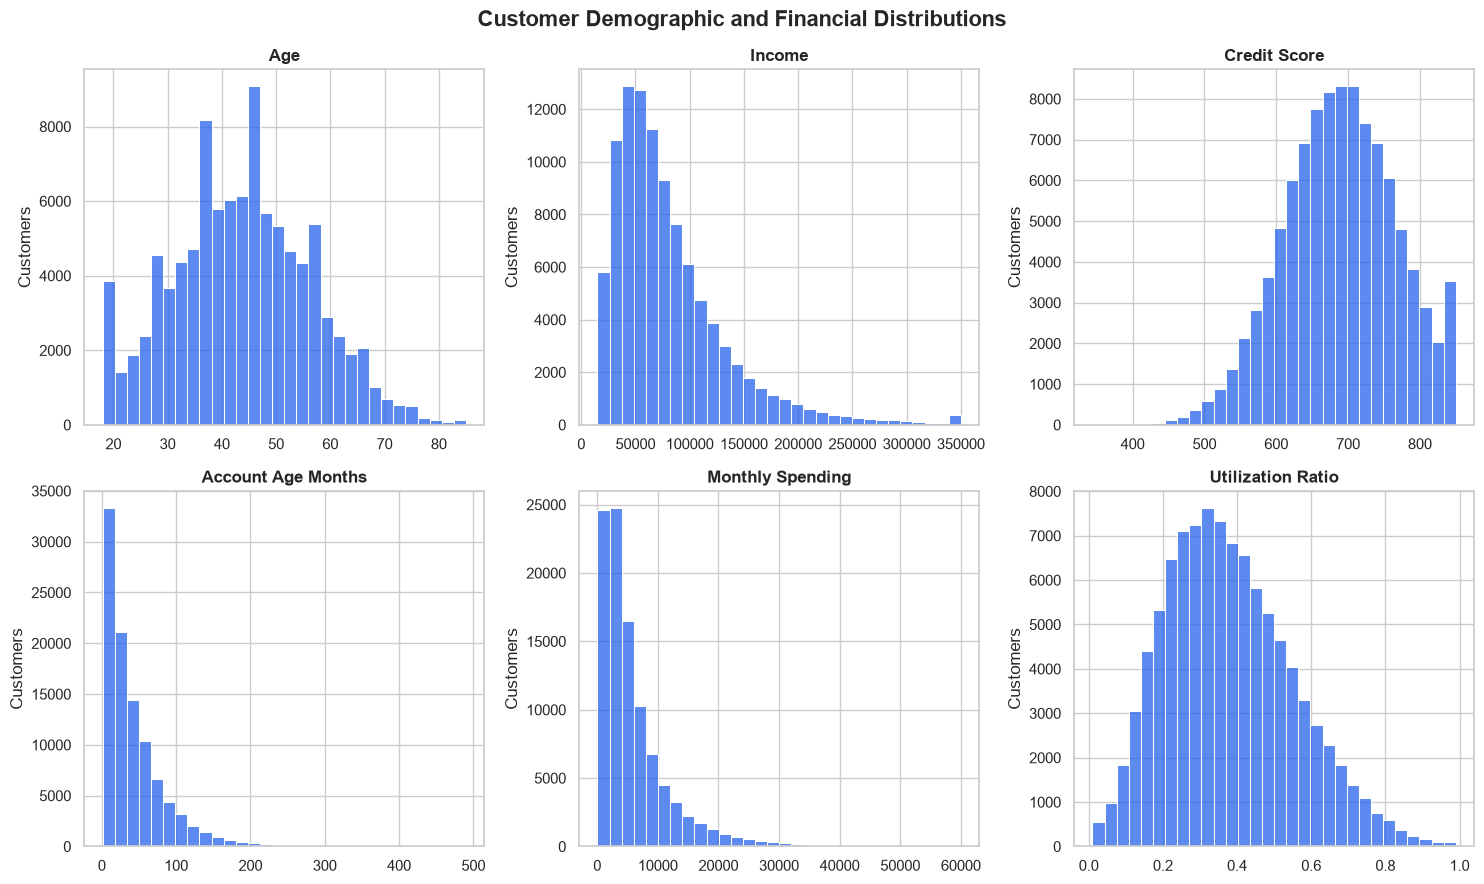

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

features = [
    "age",
    "income",
    "credit_score",
    "account_age_months",
    "monthly_spending",
    "utilization_ratio"
]

for ax, feature in zip(axes.flatten(), features):

    sns.histplot(
        data=df,
        x=feature,
        bins=30,
        color="#2563EB",
        ax=ax
    )

    ax.set_title(
        feature.replace("_", " ").title(),
        fontsize=12,
        fontweight="bold"
    )

    ax.set_xlabel("")
    ax.set_ylabel("Customers")

plt.suptitle(
    "Customer Demographic and Financial Distributions",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

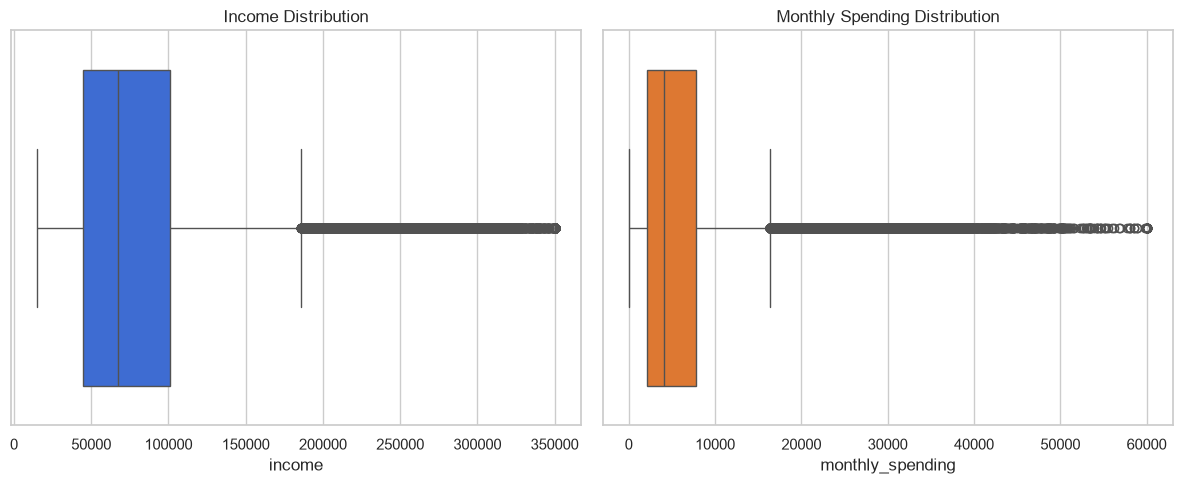

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(
    data=df,
    x="income",
    color="#2563EB",
    ax=axes[0]
)

axes[0].set_title("Income Distribution")

sns.boxplot(
    data=df,
    x="monthly_spending",
    color="#F97316",
    ax=axes[1]
)

axes[1].set_title("Monthly Spending Distribution")

plt.tight_layout()
plt.show()

## 6. Customer Churn Overview

### Business Question
What percentage of credit card customers have churned?

In [18]:
total_customers = len(df)

churned_customers = df["churned"].sum()

retained_customers = total_customers - churned_customers

churn_rate = (churned_customers / total_customers) * 100

retention_rate = 100 - churn_rate

print(f"Total Customers: {total_customers:,}")
print(f"Churned Customers: {churned_customers:,}")
print(f"Retained Customers: {retained_customers:,}")
print(f"Churn Rate: {churn_rate:.2f}%")
print(f"Retention Rate: {retention_rate:.2f}%")

Total Customers: 100,000
Churned Customers: 19,458
Retained Customers: 80,542
Churn Rate: 19.46%
Retention Rate: 80.54%


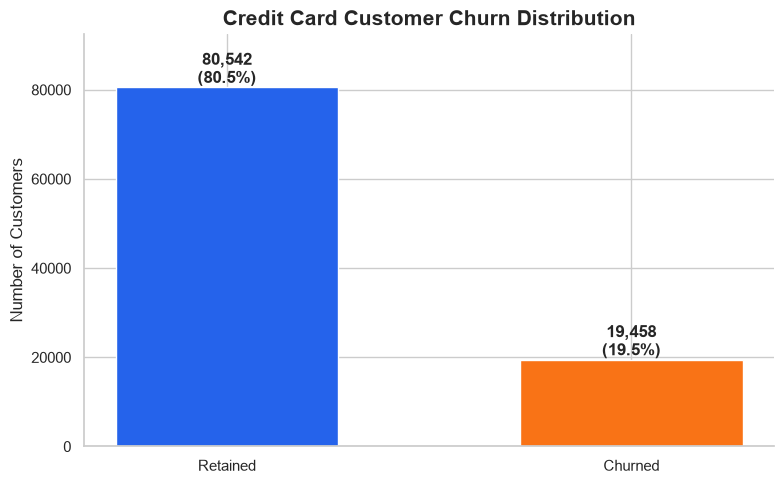

In [19]:
churn_counts = (
    df["churned"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    ["Retained", "Churned"],
    churn_counts.values,
    color=["#2563EB", "#F97316"],
    width=0.55
)

for bar in bars:
    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1000,
        f"{height:,.0f}\n({height / total_customers:.1%})",
        ha="center",
        fontweight="bold"
    )

ax.set_title(
    "Credit Card Customer Churn Distribution",
    fontsize=15,
    fontweight="bold"
)

ax.set_ylabel("Number of Customers")
ax.set_ylim(0, max(churn_counts.values) * 1.15)

sns.despine()
plt.tight_layout()
plt.show()